# Librerias y constantes

In [18]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.special import zeta
from scipy.integrate import solve_ivp, quad

OB = .27
T0 = 2.35E-10 #MeV
ME = .5 #MeV
MP = 938.27208943 #MeV
MH = 938.78 #MeV
B = 13.6 / 1E6 #MeV
ALPHA = 1/137
H0 = 1.49E-39 #MeV
H1 = np.sqrt(H0**2 * OB * (B/T0)**3)

# Ejercicios

## Item $(b)$

### Grafico de $X(T)$

/tmp/ipykernel_98036/3462476671.py:2: RuntimeWarning: overflow encountered in exp
  a = lambda T: 3.84 * eta_b(T) * (T/ME)**(3/2) * np.exp(B/T)
/tmp/ipykernel_98036/3462476671.py:3: RuntimeWarning: invalid value encountered in divide
  X_p = lambda T: (-1 + np.sqrt(1 + (4*a(T)))) / (2 * a(T))
/tmp/ipykernel_98036/3462476671.py:4: RuntimeWarning: invalid value encountered in divide
  X_m = lambda T: (-1 - np.sqrt(1 + (4*a(T)))) / (2 * a(T))


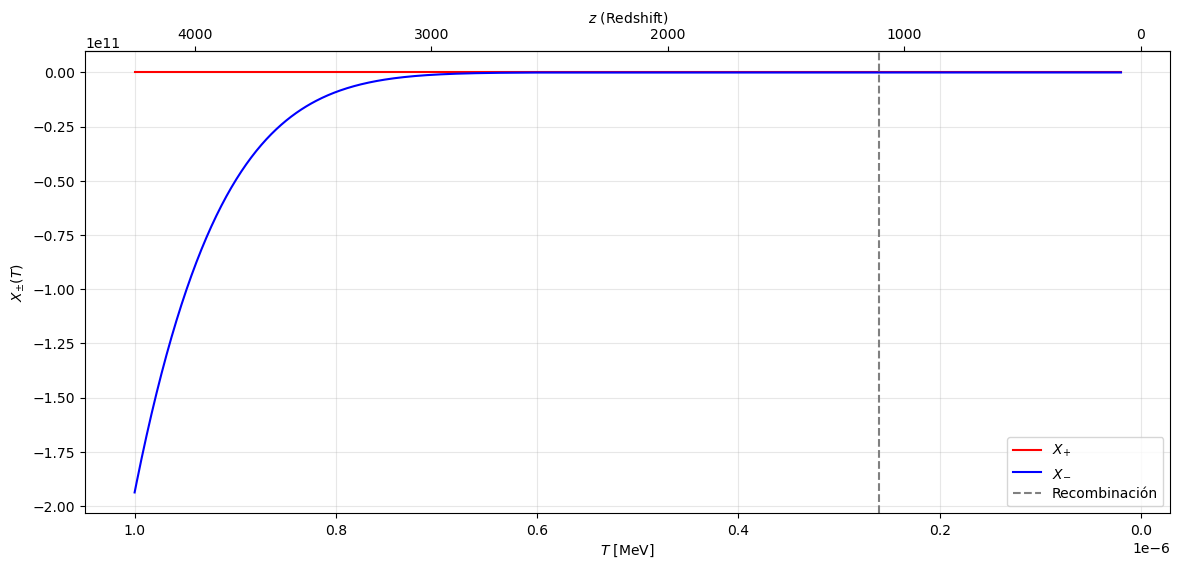

In [19]:
eta_b = lambda T: 2.68E-8 * 0.022
a = lambda T: 3.84 * eta_b(T) * (T/ME)**(3/2) * np.exp(B/T)
X_p = lambda T: (-1 + np.sqrt(1 + (4*a(T)))) / (2 * a(T))
X_m = lambda T: (-1 - np.sqrt(1 + (4*a(T)))) / (2 * a(T))
T_R = 2.6E-7 #MeV

T = np.linspace(1E-8, 1E-6, 1_000) #MeV

def T2z(T):
    return T/T0 - 1

def z2T(z):
    return T0 * (1 + z)

fig, ax = plt.subplots(figsize = (14, 6))

ax.plot(T, X_p(T), color = 'red', label = r'$X_{+}$')
ax.plot(T, X_m(T), color = 'blue', label = r'$X_{-}$')
ax.axvline(T_R, linestyle = '--', color = 'gray', label = 'Recombinación')

secax = ax.secondary_xaxis('top', functions = (T2z, z2T))
secax.set_xlabel(r'$z$ (Redshift)')

ax.set(ylabel = r'$X_{\pm}(T)$', xlabel = r'$T$ [MeV]')
ax.xaxis.set_inverted(True)
ax.grid(alpha = .3), ax.legend()

fig.savefig('Xpm.png', bbox_inches = 'tight')

### Encontrar $T_R$

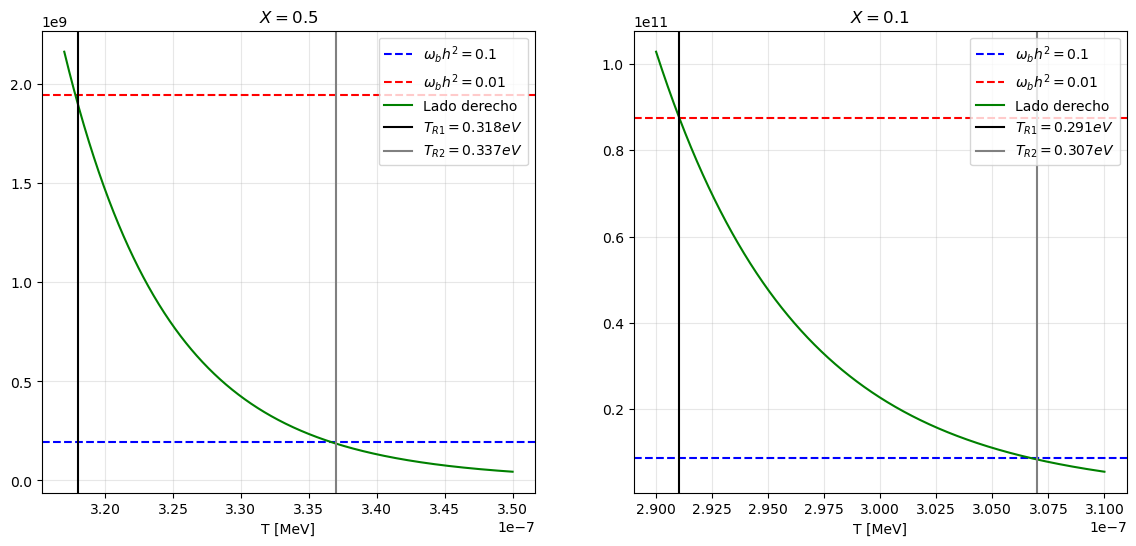

In [20]:
def izq(y, x):
    CTE = (3.84 * 2.68E-8)**(-1)
    pfactor = (1 - x)/x**2
    postfactor = y**(-1)
    return pfactor * CTE * postfactor

def der(T):
    return (T/ME)**(3/2) * np.exp(B/T)

fig, axs = plt.subplots(1, 2, figsize = (14, 6))

# Gráfico para X = .5
T_1 = np.linspace(.317E-6, .35E-6, 1000)
axs[0].axhline(izq(y = .1, x = .5), linestyle = '--',
               color = 'blue', label = r'$\omega_b h^2 = 0.1$')
axs[0].axhline(izq(y = .01, x = .5), linestyle = '--',
               color = 'red', label = r'$\omega_b h^2 = 0.01$')
axs[0].plot(T_1, der(T_1), color = 'green', label = 'Lado derecho')

axs[0].axvline(.318E-6, linestyle = '-', color = 'black', 
               label = r'$T_{R1} = 0.318 eV$')

axs[0].axvline(.337E-6, linestyle = '-', color = 'gray', 
               label = r'$T_{R2} = 0.337 eV$')
eta_b
axs[0].set(xlabel = 'T [MeV]', title = r'$X = 0.5$'), axs[0].grid(alpha = .3)
axs[0].legend(loc = 'upper right')

# Gráfico para X = .1
T_2 = np.linspace(.29E-6, .31E-6, 1000)
axs[1].axhline(izq(y = .1, x = .1), linestyle = '--',
               color = 'blue', label = r'$\omega_b h^2 = 0.1$')
axs[1].axhline(izq(y = .01, x = .1), linestyle = '--',
               color = 'red', label = r'$\omega_b h^2 = 0.01$')
axs[1].plot(T_2, der(T_2), color = 'green', label = 'Lado derecho')

axs[1].axvline(.291E-6, linestyle = '-', color = 'black', 
               label = r'$T_{R1} = 0.291 eV$')

axs[1].axvline(.307E-6, linestyle = '-', color = 'gray', 
               label = r'$T_{R2} = 0.307 eV$')

axs[1].set(xlabel = 'T [MeV]', title = r'$X = 0.1$'), axs[1].grid(alpha = .3)
axs[1].legend(loc = 'upper right')

fig.savefig('estimacion-recombinacion.png', bbox_inches = 'tight')


## Item $(c)$

La solución a resolver numéricamente es la siguiente:
$$\frac{dX}{dx} = \frac{<\sigma v> \sqrt{x}}{H(x = 1)} \bigg[ \bigg(\frac{m_e B}{2\pi}\bigg)^{3/2} \frac{e^{-x}}{x^{3/2}} (1 - X) - 2 \eta_b \zeta(3) \frac{B^3}{x^3} X^2\bigg]$$

Donde:

$$<\sigma v> = 9.78 \frac{\alpha^2}{m_e^2}\sqrt{x} \log{x}$$

In [21]:
# Lado derecho de la ecuación
f_term = lambda x: (ME * B / 2 / np.pi)**(3/2) * np.exp(-x) / x**(3/2)
s_term = lambda x:  2 * eta_b(B/x) * zeta(3) * B**3 / x**3 / np.pi**2

def dXdx(x, X):
    thermal = 9.78 * ALPHA**2 / ME**2 * np.sqrt(x) * np.log(x)
    glob_factor = thermal * np.sqrt(x) / H1
    
    f_factor = f_term(x)*(1 - X)
    s_factor = s_term(x) * X**2
    return glob_factor * (f_factor - s_factor)

# Condición inicial y límites
T_0, T_F = .8E-6, .15E-6 #MeV
x0, xF = B/T_0, B/T_F

print(x0), print(xF)

X0 = X_p(T_0)

17.0
90.66666666666667


Como estoy teniendo problemas en resolver la ecuación diferencial voy a tomar el consejo visto en clase y graficar cada uno de los dos términos para ver si hay algún tipo de problemática en cuestión de órdenes de magnitud

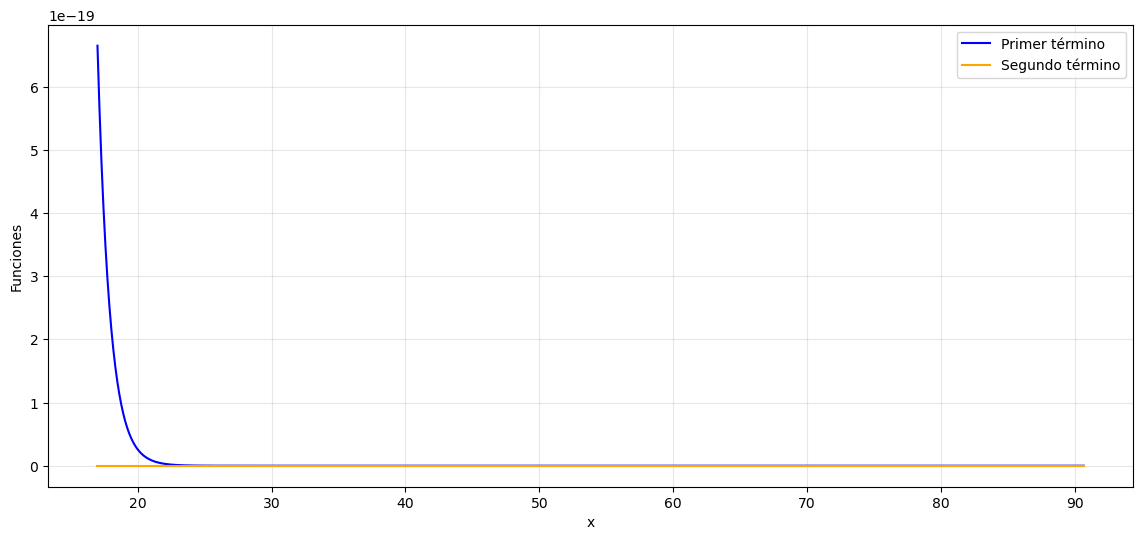

In [22]:
xtest = np.linspace(x0, xF, 1_000)

fig, ax = plt.subplots(figsize = (14, 6))

ax.plot(xtest, f_term(xtest), color = 'blue', label = 'Primer término')
ax.plot(xtest, s_term(xtest), color = 'orange', label = 'Segundo término')

ax.set(xlabel = 'x', ylabel = 'Funciones'), ax.grid(alpha = .3)
ax.legend()

plt.show()

Como se puede notar existe una gran diferencia en órdenes de magnitud entre los factores que acompañan al $(1 - X)$ (primer término) y $X^2$ (segundo término):
$$\text{Primer término:} \bigg(\frac{m_e B}{2\pi}\bigg)^{3/2} \frac{e^{-x}}{x^{3/2}} $$
$$\text{Segundo término:} 2 \eta_b \zeta(3) \frac{B^3}{x^3}$$

Dado este problema entiendo que el método de integración *RK45* no es el adecuado para este tipo de ecuaciones integrales, y como no cursé la meteria *Cálculo numérico* y es una de las primeras veces que resuelvo ecuaciones diferenciales numéricamente le pregunté a **Claude** que solver puedo utilizar.

Luego de un rato de conversación me dijo que utilice para probar el método **Radau** y que coloque los parámetros *rtol* y *atol* con los valores que se muestran a continuacion. Además sin pedirselo me recomendó poner los ejes logarítmicos, asique una vez que lo vi lo tuve en cuenta.

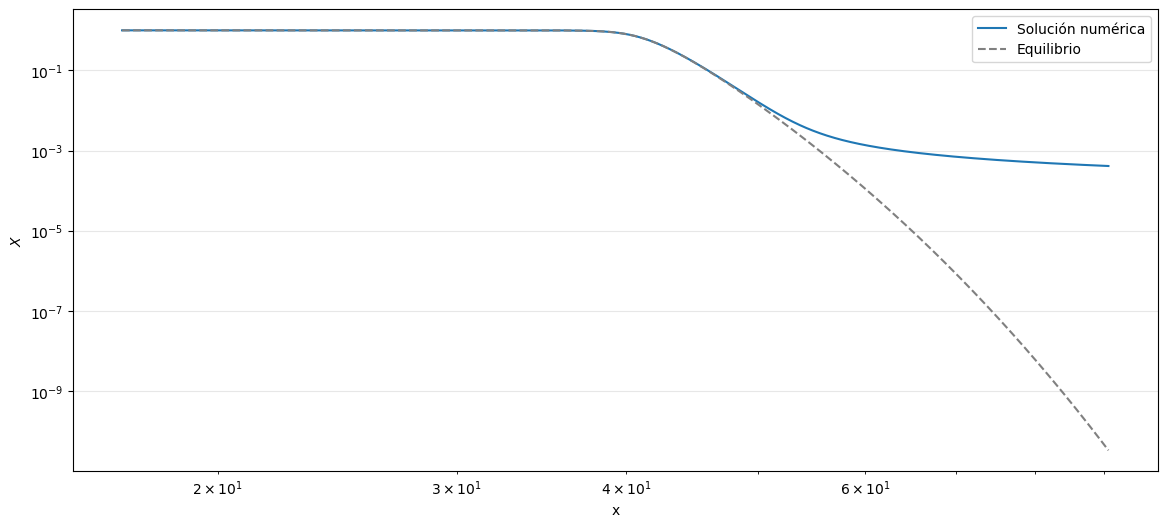

(None, None)

In [24]:
sol = solve_ivp(dXdx, [x0, xF], [X0], method='Radau', rtol=1e-8, atol=1e-12, dense_output=True)

def jac(x, X):
    thermal = 9.78*ALPHA**2/ME**2*np.sqrt(x)*np.log(x)
    g = thermal*np.sqrt(x)/H1
    return [[g*(-f_term(x) - 2*s_term(x)*X[0])]]

fig, ax = plt.subplots(figsize = (14, 6))

ax.plot(xtest, sol.sol(xtest)[0], label = 'Solución numérica')
ax.plot(xtest, X_p(B/xtest), linestyle = '--', 
        color = 'gray', label = 'Equilibrio')

ax.set(xlabel = 'x', ylabel = r'$X$', yscale = 'log', xscale = 'log'), ax.grid(alpha = .3), ax.legend()
fig.savefig('Solucion_numerica.png', bbox_inches = 'tight'), plt.show()